# MedVision Smart — Segmentation biomédicale intelligente
## Étape 1 · Notebook 01 : Exploration, nettoyage et découpage des données

**Équipe :** Abderrahman Ghazouani · Hiba Hamrani · Anas Latifi

---

### Problématique

L'échographie mammaire est un examen essentiel pour détecter les tumeurs du sein. Délimiter précisément le contour d'une tumeur est **long à faire à la main** et **varie d'un radiologue à l'autre**.

L'objectif du projet est de **segmenter automatiquement** les tumeurs : pour chaque image, un modèle produit un **masque binaire** où chaque pixel vaut **1 (tumeur)** ou **0 (fond)**. Une plateforme permettra ensuite à un humain de **comparer, corriger et valider** ces masques.

### Jeu de données : BUSI

*Breast Ultrasound Images Dataset* (Kaggle) : 780 échographies réparties en 3 classes (**benign**, **malignant**, **normal**), accompagnées de masques tracés par des radiologues. Ces masques sont la **vérité terrain** que les modèles doivent apprendre à reproduire.

### Les 4 algorithmes comparés dans l'étape 1

| # | Algorithme | Rôle | Question posée |
|---|---|---|---|
| 1 | Seuillage d'Otsu | Baseline simple, sans apprentissage | Faut-il vraiment du deep learning ? |
| 2 | CNN encodeur-décodeur simple | Modèle classique, sans skip connections | L'apprentissage seul suffit-il ? |
| 3 | U-Net | Modèle de référence (énoncé) | Les skip connections aident-elles ? |
| 4 | U-Net++ | Architecture avancée imposée | Les skip connections denses valent-elles leur coût ? |

### Organisation des notebooks

| Notebook | Contenu |
|---|---|
| **01_exploration** (ce notebook) | Exploration, nettoyage, découpage train/val/test → `splits.csv` |
| 02_baselines | Otsu + CNN simple, fonctions de métriques |
| 03_unet_unetpp | U-Net, U-Net++, réglage des hyperparamètres (GPU) |
| 04_evaluation | Évaluation finale sur le test, tableau comparatif, analyse d'erreurs |

### Plan de ce notebook

0. Préparation de l'environnement
1. Exploration des données
2. Nettoyage : masques multiples, cohérence, doublons exacts (MD5), quasi-doublons (pHash + corrélation)
3. Découpage train / validation / test **par groupe**
4. Fonctions partagées (`utils.py`)
5. Synthèse

### Résultats clés

| | |
|---|---|
| Images d'origine | 780 |
| Doublons exacts retirés (classes contradictoires) | 2 |
| Groupes de quasi-doublons détectés | 137 (310 images) |
| Groupes contradictoires retirés | 7 (16 images) |
| **Dataset final** | **762 images** (427 benign, 204 malignant, 131 normal) |
| **Découpage** | **537 train / 114 val / 111 test**, par groupe, sans fuite |

---
## 0. Préparation de l'environnement

### Les bibliothèques utilisées

| Bibliothèque | Rôle dans ce notebook |
|---|---|
| `os`, `glob` | Parcourir les dossiers et trouver les fichiers |
| `hashlib` | Calculer une « empreinte » exacte (MD5) de chaque image pour détecter les doublons exacts |
| `imagehash`, `PIL` | Calculer une empreinte **perceptuelle** pour détecter les **quasi-doublons** |
| `numpy` | Manipuler les images comme des tableaux de nombres |
| `pandas` | Ranger les informations sur chaque image dans un tableau (DataFrame) |
| `cv2` (OpenCV) | Lire les images et les masques |
| `matplotlib`, `seaborn` | Tracer les graphiques |
| `sklearn` | Faire le découpage train / validation / test stratifié |

### Pourquoi fixer une « seed » ?

Plusieurs opérations utilisent le hasard (choisir des exemples à afficher, mélanger les données avant le découpage). En fixant la **seed** (graine aléatoire) à 42, le hasard devient **reproductible** : si on relance le notebook, on obtient **exactement les mêmes résultats**. C'est une exigence du prof (*pipeline reproductible*).

⚠️ Si `import imagehash` donne une erreur, installe-le une fois dans le terminal (avec `(.venv)` activé) : `pip install imagehash`

### Les chemins

- `DATA_DIR` : là où se trouve le dataset BUSI dézippé.
- `OUT_DIR` : un dossier `outputs` où on enregistre les figures (pour le rapport) et les fichiers produits.

⚠️ Le notebook doit être lancé **depuis le dossier `medvision-smart`**, sinon le chemin `data/...` ne sera pas trouvé. La dernière ligne de la cellule vérifie justement que le dossier existe : elle doit afficher `True`.

In [27]:
# --- Bibliothèques ---
import os
import glob
import hashlib
import random

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import imagehash          # hash perceptuel (quasi-doublons)
from PIL import Image

# --- Reproductibilité ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Chemins ---
DATA_DIR = "data/Dataset_BUSI_with_GT"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Constantes ---
CLASSES = ["benign", "malignant", "normal"]
COULEURS = {"benign": "#4C72B0", "malignant": "#C44E52", "normal": "#55A868"}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)

print("Dossier du dataset trouvé :", os.path.isdir(DATA_DIR))

Dossier du dataset trouvé : True


---
## 1. Exploration des données

Avant de toucher aux modèles, il faut **connaître ses données** : combien d'images, dans quelles classes, de quelle taille, à quoi ressemblent les tumeurs. Chaque observation de cette partie justifie une décision prise plus tard (stratification, redimensionnement, analyse des petites tumeurs…).

### 1.1 Inventaire des fichiers

Dans chaque dossier de classe, les fichiers sont nommés ainsi :

| Fichier | Contenu |
|---|---|
| `benign (1).png` | l'échographie |
| `benign (1)_mask.png` | le masque de la tumeur |
| `benign (1)_mask_1.png` | un **deuxième** masque, s'il y a une deuxième lésion |

Le code ci-dessous parcourt les 3 dossiers et construit un tableau avec **une ligne par échographie** :

- `id` : le nom de l'image, sans `.png` (ex. `benign (1)`) ;
- `classe` : benign, malignant ou normal ;
- `image_path` : le chemin de l'image ;
- `mask_paths` : le ou les chemins des masques, séparés par `;` ;
- `nb_masques` : le nombre de masques trouvés.

Les fichiers contenant `_mask` sont ignorés dans la boucle principale, puisque ce ne sont pas des échographies. `replace("\\", "/")` uniformise les chemins Windows pour que le fichier final marche sur tous les PC du groupe.

In [28]:
rows = []
for classe in CLASSES:
    for img_path in sorted(glob.glob(os.path.join(DATA_DIR, classe, "*.png"))):
        if "_mask" in os.path.basename(img_path):
            continue  # on ignore les fichiers masques
        base = img_path[:-4]  # chemin sans ".png"
        masks = sorted(glob.glob(base + "_mask*.png"))
        rows.append({
            "id": os.path.basename(base),
            "classe": classe,
            "image_path": img_path.replace("\\", "/"),
            "mask_paths": ";".join(m.replace("\\", "/") for m in masks),
            "nb_masques": len(masks),
        })

df = pd.DataFrame(rows)
print("Nombre total d'échographies :", len(df))
df.head()

Nombre total d'échographies : 780


,id,classe,image_path,mask_paths,nb_masques
0,benign (1),benign,data/Dataset_BUSI_with_GT/benign/benign (1).png,data/Dataset_BUSI_with_GT/benign/benign (1)_mask.png,1
1,benign (10),benign,data/Dataset_BUSI_with_GT/benign/benign (10).png,data/Dataset_BUSI_with_GT/benign/benign (10)_mask.png,1
2,benign (100),benign,data/Dataset_BUSI_with_GT/benign/benign (100).png,data/Dataset_BUSI_with_GT/benign/benign (100)_mask.png;d...,2
3,benign (101),benign,data/Dataset_BUSI_with_GT/benign/benign (101).png,data/Dataset_BUSI_with_GT/benign/benign (101)_mask.png,1
4,benign (102),benign,data/Dataset_BUSI_with_GT/benign/benign (102).png,data/Dataset_BUSI_with_GT/benign/benign (102)_mask.png,1


### 1.2 Répartition des classes

On compte le nombre d'images par classe et leur pourcentage. C'est important car si une classe est **beaucoup plus rare**, elle risque d'être **mal représentée** dans le jeu de test si on découpe au hasard.

,nb_images,pourcentage (%)
classe,,
benign,437,56.0
malignant,210,26.9
normal,133,17.1


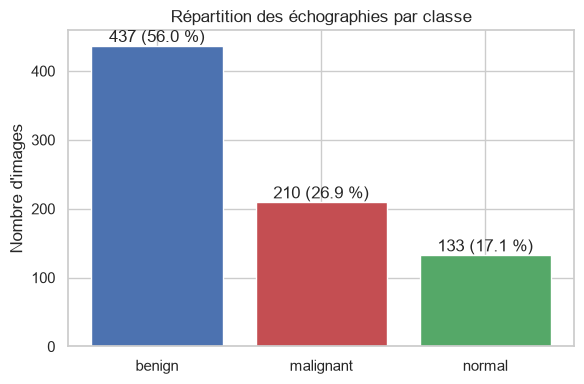

In [29]:
repartition = df["classe"].value_counts().reindex(CLASSES)
pourcentage = (repartition / len(df) * 100).round(1)
display(pd.DataFrame({"nb_images": repartition, "pourcentage (%)": pourcentage}))

fig, ax = plt.subplots(figsize=(6, 4))
barres = ax.bar(repartition.index, repartition.values,
                color=[COULEURS[c] for c in repartition.index])
ax.bar_label(barres, labels=[f"{n} ({p} %)" for n, p in zip(repartition, pourcentage)])
ax.set_title("Répartition des échographies par classe")
ax.set_ylabel("Nombre d'images")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/repartition_classes.png", dpi=150)
plt.show()

### 1.3 Nombre de masques par image

Normalement, une image = un masque. Mais quand une échographie contient **plusieurs lésions**, BUSI fournit **un fichier masque par lésion**. On compte ces cas, puis on affiche la liste des images concernées.

In [30]:
display(df["nb_masques"].value_counts().sort_index().rename("nb_images").to_frame())

multi = df[df["nb_masques"] > 1]
print(f"{len(multi)} images ont plusieurs masques :")
display(multi[["id", "classe", "nb_masques"]])

,nb_images
nb_masques,
1,763
2,16
3,1


17 images ont plusieurs masques :


,id,classe,nb_masques
2,benign (100),benign,2
71,benign (163),benign,2
82,benign (173),benign,2
91,benign (181),benign,2
106,benign (195),benign,3
167,benign (25),benign,2
240,benign (315),benign,2
274,benign (346),benign,2
333,benign (4),benign,2
361,benign (424),benign,2


**Observations :**

- **780 images** : 437 benign (56 %), 210 malignant (27 %), 133 normal (17 %).
  → Les classes sont **déséquilibrées** : il y a deux fois plus d'images bénignes que malignes. Le découpage devra être **stratifié par classe**, pour que train, validation et test gardent les mêmes proportions.
- **17 images ont plusieurs masques** (16 avec 2 masques, 1 avec 3), car elles contiennent plusieurs lésions.
  → Un modèle attend **un seul masque par image** : ils seront **fusionnés** au nettoyage.
- Les images **normal** n'ont pas de tumeur : leur masque doit être **entièrement noir**. On le vérifiera.

### 1.4 Visualisation d'exemples

On définit d'abord deux fonctions qu'on réutilisera partout :

- **`lire_image(chemin)`** : lit l'échographie en **niveaux de gris** (`IMREAD_GRAYSCALE`). Les fichiers BUSI sont enregistrés en couleur, mais l'échographie est en noir et blanc : un seul canal suffit.
- **`lire_masque(mask_paths)`** : lit **tous** les masques d'une image et les **fusionne** :
  - `> 0` transforme chaque masque en vrai/faux (pixel de tumeur ou non) ;
  - `|` est le **OU logique** : un pixel est « tumeur » s'il l'est **dans au moins un** des masques ;
  - le résultat est converti en `uint8` avec des valeurs **0 ou 1**.

Ensuite on affiche, pour un exemple tiré au hasard dans chaque classe : l'image, son masque, et le masque **superposé en rouge** sur l'image (`alpha=0.4` = transparence), pour vérifier que le contour tombe bien sur la tumeur.

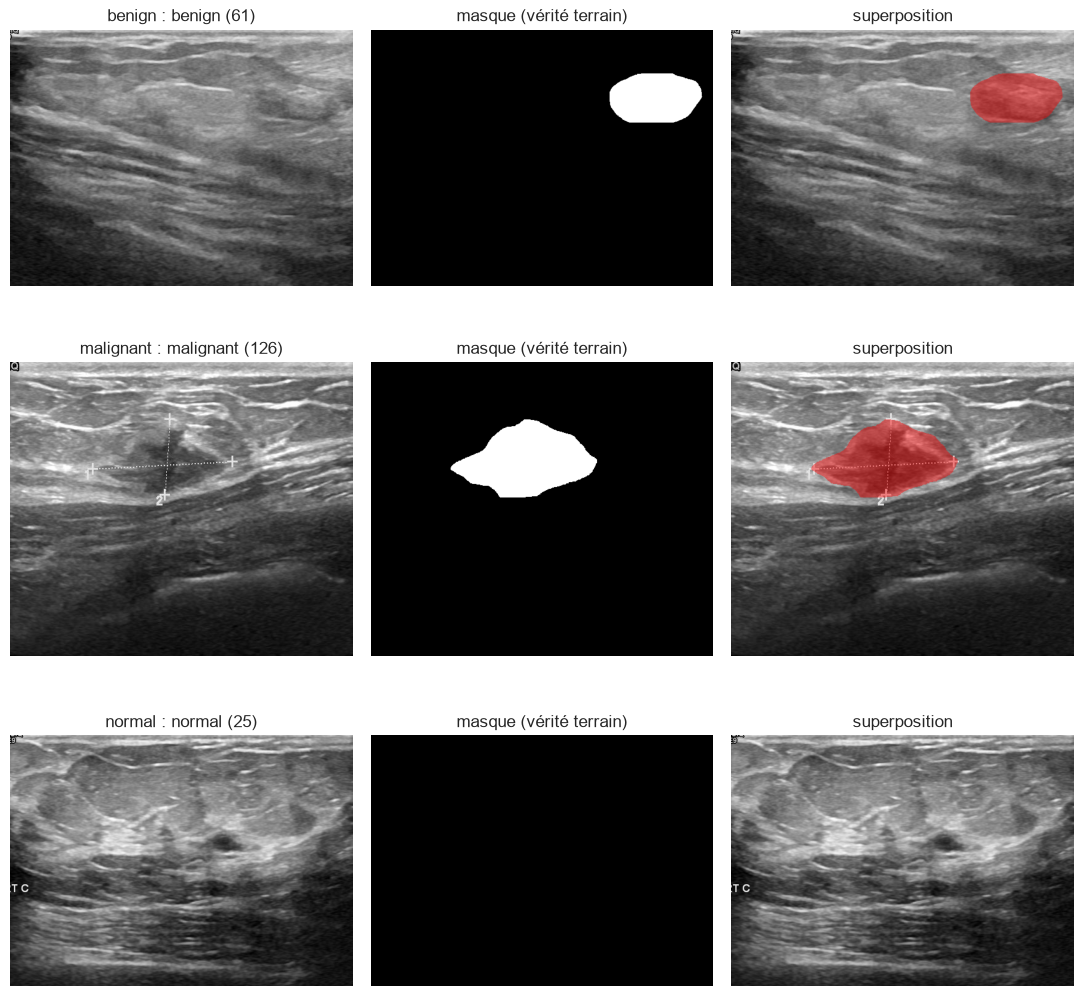

In [31]:
def lire_image(chemin):
    # Lit une échographie en niveaux de gris (tableau 2D de valeurs 0-255).
    return cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)


def lire_masque(mask_paths):
    # Lit et fusionne (OU logique) tous les masques d'une image. Renvoie un tableau 0/1.
    masque = None
    for chemin in mask_paths.split(";"):
        m = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) > 0
        masque = m if masque is None else (masque | m)
    return masque.astype(np.uint8)


fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for i, classe in enumerate(CLASSES):
    exemple = df[df["classe"] == classe].sample(1, random_state=SEED).iloc[0]
    img = lire_image(exemple["image_path"])
    masque = lire_masque(exemple["mask_paths"])

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"{classe} : {exemple['id']}")
    axes[i, 1].imshow(masque, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("masque (vérité terrain)")
    axes[i, 2].imshow(img, cmap="gray")
    axes[i, 2].imshow(np.ma.masked_where(masque == 0, masque), cmap="autumn", alpha=0.45)
    axes[i, 2].set_title("superposition")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/exemples_par_classe.png", dpi=150)
plt.show()

**Ce qu'on remarque en général sur BUSI :**

- Les tumeurs apparaissent comme des **zones sombres** (hypoéchogènes).
- Les tumeurs **bénignes** ont souvent un contour **rond et régulier** ; les **malignes** un contour plus **irrégulier**, parfois flou.
- L'image contient beaucoup de **bruit** (le « grain » typique de l'échographie) et parfois des **annotations** de l'appareil sur les bords.
- D'autres zones sombres qui **ne sont pas des tumeurs** existent : c'est ce qui va piéger la baseline d'Otsu, qui ne fait que séparer le sombre du clair.

### 1.5 Analyse de chaque image

On parcourt maintenant **toutes** les images une seule fois, et pour chacune on calcule :

| Colonne | Signification | Pourquoi c'est utile |
|---|---|---|
| `hauteur`, `largeur` | Taille de l'image en pixels | Décider de la taille de redimensionnement |
| `taille_ok` | L'image et son masque ont-ils la même taille ? | Détecter des fichiers incohérents |
| `ratio_tumeur` | Part de l'image occupée par la tumeur (moyenne du masque) | Repérer les petites tumeurs, difficiles à segmenter |
| `nb_lesions` | Nombre de zones blanches séparées dans le masque fusionné | Vérifier les images à plusieurs lésions |
| `hash` | Empreinte MD5 des pixels de l'image | Détecter les **doublons** (même image = même empreinte) |

`cv2.connectedComponents` compte les « îlots » de pixels blancs ; on enlève 1 car il compte aussi le fond. `tqdm` affiche une barre de progression.

In [32]:
infos = []
for _, ligne in tqdm(df.iterrows(), total=len(df), desc="Analyse des images"):
    img = lire_image(ligne["image_path"])
    masque = lire_masque(ligne["mask_paths"])
    infos.append({
        "hauteur": img.shape[0],
        "largeur": img.shape[1],
        "taille_ok": img.shape == masque.shape,
        "ratio_tumeur": float(masque.mean()),
        "nb_lesions": cv2.connectedComponents(masque)[0] - 1,
        "hash": hashlib.md5(str(img.shape).encode() + img.tobytes()).hexdigest(),
    })

df = pd.concat([df, pd.DataFrame(infos)], axis=1)
df.head()

Analyse des images: 100%|██████████| 780/780 [00:16<00:00, 46.97it/s]


,id,classe,image_path,mask_paths,nb_masques,hauteur,largeur,taille_ok,ratio_tumeur,nb_lesions,hash
0,benign (1),benign,data/Dataset_BUSI_with_GT/benign/benign (1).png,data/Dataset_BUSI_with_GT/benign/benign (1)_mask.png,1,471,562,True,0.003717,1,30110d92f6ee8768f3eeb3a3cafbce85
1,benign (10),benign,data/Dataset_BUSI_with_GT/benign/benign (10).png,data/Dataset_BUSI_with_GT/benign/benign (10)_mask.png,1,585,683,True,0.082387,1,515d4fde4762756f496d7958cc179ee0
2,benign (100),benign,data/Dataset_BUSI_with_GT/benign/benign (100).png,data/Dataset_BUSI_with_GT/benign/benign (100)_mask.png;d...,2,473,323,True,0.065526,2,4d97962935ecb4d50628a7711e177228
3,benign (101),benign,data/Dataset_BUSI_with_GT/benign/benign (101).png,data/Dataset_BUSI_with_GT/benign/benign (101)_mask.png,1,473,563,True,0.015648,1,1802770b76fd8105e5c736436fb95001
4,benign (102),benign,data/Dataset_BUSI_with_GT/benign/benign (102).png,data/Dataset_BUSI_with_GT/benign/benign (102)_mask.png,1,610,634,True,0.048759,1,8c16246073bbd3303f6a76415c18f0b3


### 1.6 Taille des images

Un réseau de neurones attend des images **toutes de la même taille**. On regarde donc si les tailles varient.

,hauteur,largeur
count,780.0,780.0
mean,501.0,616.0
std,77.0,122.0
min,310.0,190.0
25%,465.0,554.0
50%,474.0,564.0
75%,574.0,714.0
max,719.0,1048.0


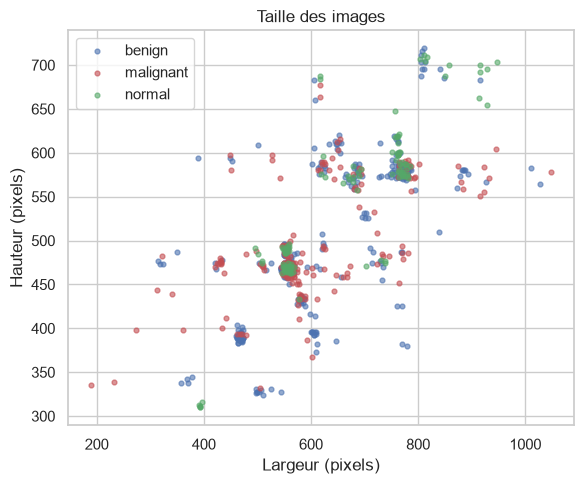

Images dont le masque n'a pas la même taille : 0


In [33]:
display(df[["hauteur", "largeur"]].describe().round(0))

fig, ax = plt.subplots(figsize=(6, 5))
for classe in CLASSES:
    sous = df[df["classe"] == classe]
    ax.scatter(sous["largeur"], sous["hauteur"], s=12, alpha=0.6,
               label=classe, color=COULEURS[classe])
ax.set_xlabel("Largeur (pixels)")
ax.set_ylabel("Hauteur (pixels)")
ax.set_title("Taille des images")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/tailles_images.png", dpi=150)
plt.show()

print("Images dont le masque n'a pas la même taille :", (~df["taille_ok"]).sum())

**Interprétation :** les images n'ont **pas toutes la même taille** (en moyenne autour de 500 × 600 pixels sur BUSI). Il faudra donc les **redimensionner** à une taille fixe avant l'entraînement. L'énoncé demande **128 à 256 px** : on testera **128 et 256** comme hyperparamètre.

- 128 px : entraînement **plus rapide**, mais les **petits détails** du contour sont perdus.
- 256 px : contours plus **précis**, mais **4 fois plus de pixels** à traiter.

On vérifie aussi que chaque masque a **exactement la taille de son image**, sinon la superposition pixel par pixel n'aurait pas de sens.

### 1.7 Taille des tumeurs

`ratio_tumeur` indique quelle **part de l'image** est occupée par la tumeur. Par exemple, 0,05 = 5 % de l'image. On compare les classes benign et malignant (les images normal valent 0, sans tumeur).

,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
benign,437.0,6.88,8.34,0.28,1.51,3.79,9.13,51.30
malignant,210.0,14.74,10.71,0.51,6.05,12.06,20.66,56.29


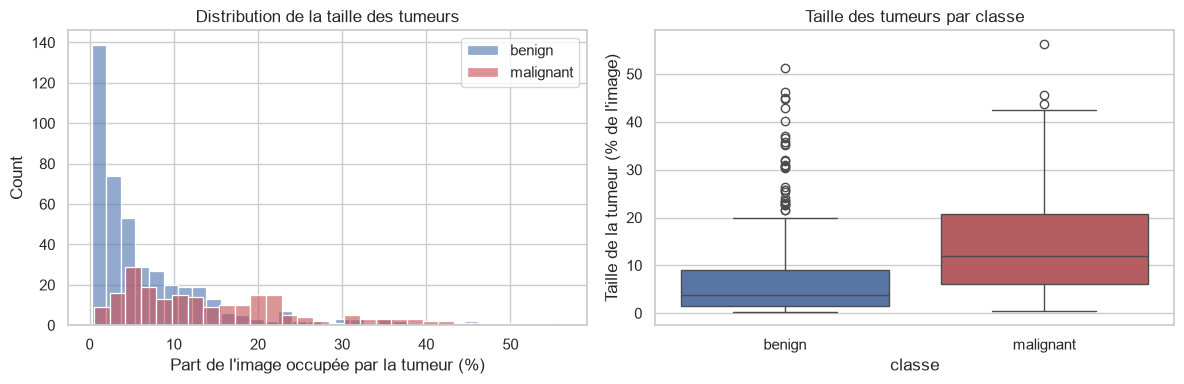

Tumeurs occupant moins de 1 % de l'image : 61 (9.4 % des images avec tumeur)


In [34]:
tumeurs = df[df["classe"] != "normal"].copy()
tumeurs["ratio_tumeur_%"] = tumeurs["ratio_tumeur"] * 100

display(tumeurs.groupby("classe")["ratio_tumeur_%"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for classe in ["benign", "malignant"]:
    sns.histplot(tumeurs[tumeurs["classe"] == classe]["ratio_tumeur_%"], bins=30,
                 ax=axes[0], color=COULEURS[classe], label=classe, alpha=0.6)
axes[0].set_xlabel("Part de l'image occupée par la tumeur (%)")
axes[0].set_title("Distribution de la taille des tumeurs")
axes[0].legend()

sns.boxplot(data=tumeurs, x="classe", y="ratio_tumeur_%", ax=axes[1],
            hue="classe", palette=COULEURS, legend=False)
axes[1].set_ylabel("Taille de la tumeur (% de l'image)")
axes[1].set_title("Taille des tumeurs par classe")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/taille_tumeurs.png", dpi=150)
plt.show()

petites = (tumeurs["ratio_tumeur_%"] < 1).sum()
print(f"Tumeurs occupant moins de 1 % de l'image : {petites} "
      f"({petites / len(tumeurs) * 100:.1f} % des images avec tumeur)")

**Interprétation :**

- La taille des tumeurs **varie énormément** : certaines occupent une grande partie de l'image, d'autres **moins de 1 %**.
- Les **petites tumeurs** sont les plus difficiles : quelques pixels d'erreur suffisent à faire chuter le Dice. Elles seront un **cas à part dans l'analyse d'erreurs** (notebook 04).
- Le **déséquilibre pixel** est fort : même dans une image avec tumeur, la grande majorité des pixels sont du **fond**. C'est pour ça qu'on teste une perte **Dice** (qui regarde la forme globale de la tumeur) en plus de la **BCE** (qui juge chaque pixel et peut être « dominée » par le fond).

---
## 2. Nettoyage

Le nettoyage corrige les problèmes trouvés à l'exploration **avant** le découpage. Ordre important : si on découpait d'abord, deux copies d'une même image pourraient se retrouver l'une dans le train et l'autre dans le test, ce qui serait une **fuite de données**.

### 2.1 Fusion des masques multiples

La fonction `lire_masque` fusionne déjà les masques. On le vérifie visuellement sur quelques images concernées : chaque masque séparé, puis le masque fusionné. On compare aussi `nb_masques` (nombre de fichiers) et `nb_lesions` (nombre de zones dans le masque fusionné) : ils peuvent différer si deux lésions se touchent.

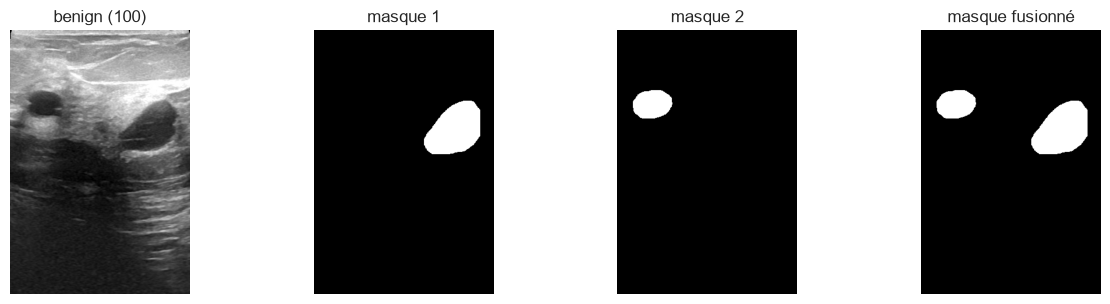

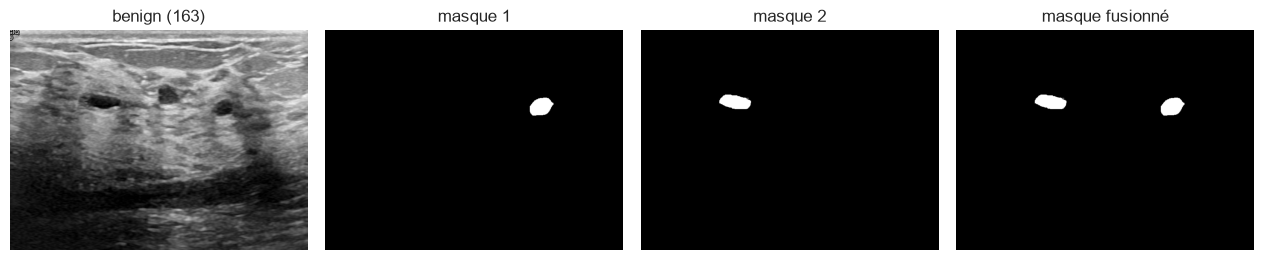

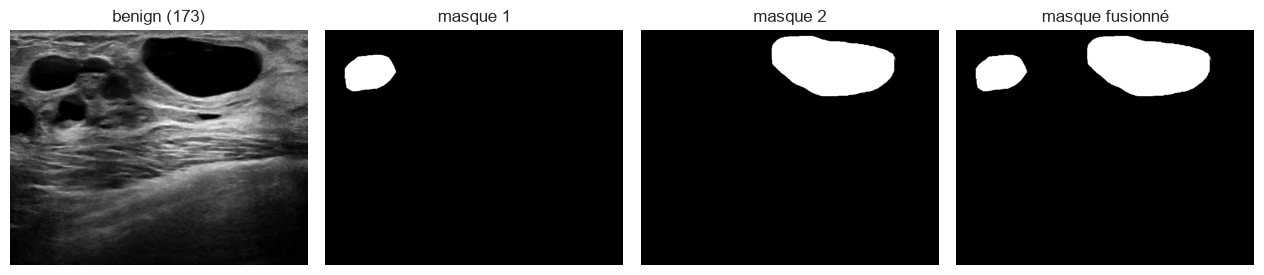

,id,classe,nb_masques,nb_lesions
2,benign (100),benign,2,2
71,benign (163),benign,2,2
82,benign (173),benign,2,2
91,benign (181),benign,2,1
106,benign (195),benign,3,2
167,benign (25),benign,2,2
240,benign (315),benign,2,2
274,benign (346),benign,2,2
333,benign (4),benign,2,2
361,benign (424),benign,2,2


In [35]:
exemples_multi = df[df["nb_masques"] > 1].head(3)

for _, ligne in exemples_multi.iterrows():
    chemins = ligne["mask_paths"].split(";")
    n = len(chemins)
    fig, axes = plt.subplots(1, n + 2, figsize=(3.2 * (n + 2), 3.2))
    axes[0].imshow(lire_image(ligne["image_path"]), cmap="gray")
    axes[0].set_title(ligne["id"])
    for k, chemin in enumerate(chemins):
        axes[k + 1].imshow(cv2.imread(chemin, cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[k + 1].set_title(f"masque {k + 1}")
    axes[-1].imshow(lire_masque(ligne["mask_paths"]), cmap="gray")
    axes[-1].set_title("masque fusionné")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

display(df[df["nb_masques"] > 1][["id", "classe", "nb_masques", "nb_lesions"]])

### 2.2 Cohérence des masques avec les classes

Deux règles doivent être respectées :

1. Une image **normal** doit avoir un masque **vide** (`ratio_tumeur = 0`).
2. Une image **benign** ou **malignant** doit avoir un masque **non vide** (`ratio_tumeur > 0`).

Les images qui ne respectent pas ces règles sont des **anomalies d'annotation** : on les affiche pour décider quoi en faire.

In [36]:
normal_non_vide = df[(df["classe"] == "normal") & (df["ratio_tumeur"] > 0)]
tumeur_vide = df[(df["classe"] != "normal") & (df["ratio_tumeur"] == 0)]

print("Images 'normal' avec un masque non vide :", len(normal_non_vide))
print("Images 'benign/malignant' avec un masque vide :", len(tumeur_vide))

anomalies = pd.concat([normal_non_vide, tumeur_vide])
if len(anomalies) > 0:
    display(anomalies[["id", "classe", "ratio_tumeur"]])

Images 'normal' avec un masque non vide : 0
Images 'benign/malignant' avec un masque vide : 0


**Résultat :** 0 anomalie. Toutes les images *normal* ont un masque vide, et toutes les images *benign* / *malignant* ont une tumeur annotée.

### 2.3 Doublons exacts (empreinte MD5)

BUSI contient quelques **images en double** (la même échographie enregistrée deux fois). C'est dangereux : si une copie est dans le **train** et l'autre dans le **test**, le modèle sera testé sur une image qu'il a **déjà vue**, et ses résultats seront **trop optimistes**. C'est une **fuite de données**.

**Méthode :** deux images identiques au pixel près ont la même empreinte `hash`. On regroupe les images par empreinte.

**Règle de nettoyage :**

- doublons **dans la même classe** → on garde **une seule copie** ;
- même image dans **deux classes différentes** → l'étiquette est **contradictoire**, on **retire toutes les copies**.

In [37]:
groupes = df.groupby("hash")
doublons = df[df["hash"].isin([h for h, g in groupes if len(g) > 1])].sort_values("hash")

print("Images faisant partie d'un groupe de doublons :", len(doublons))
print("Nombre de groupes de doublons :", doublons["hash"].nunique())
if len(doublons) > 0:
    display(doublons[["id", "classe", "hash"]])

Images faisant partie d'un groupe de doublons : 2
Nombre de groupes de doublons : 1


,id,classe,hash
371,benign (433),benign,8b2e92cd4bf81b6885e30115ef400d26
488,malignant (145),malignant,8b2e92cd4bf81b6885e30115ef400d26


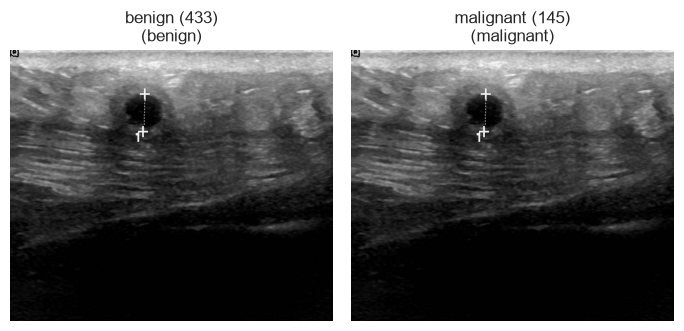

In [38]:
# Affiche les premiers groupes de doublons côte à côte pour vérifier à l'œil
for h, groupe in list(doublons.groupby("hash"))[:3]:
    fig, axes = plt.subplots(1, len(groupe), figsize=(3.5 * len(groupe), 3.5))
    axes = np.atleast_1d(axes)
    for ax, (_, ligne) in zip(axes, groupe.iterrows()):
        ax.imshow(lire_image(ligne["image_path"]), cmap="gray")
        ax.set_title(f"{ligne['id']}\n({ligne['classe']})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 2.4 Application du nettoyage

On construit le dataset propre `df_clean` :

1. on retire les **anomalies** trouvées en 2.2 (s'il y en a) ;
2. on retire les images présentes dans **plusieurs classes** ;
3. pour les autres doublons, on garde **la première copie** (`drop_duplicates`).

On affiche ensuite le **bilan** : combien d'images ont été retirées et la nouvelle répartition des classes. Ces chiffres iront dans le rapport.

In [39]:
# 1. Hash présents dans plusieurs classes différentes -> étiquette contradictoire
hash_conflit = df.groupby("hash")["classe"].nunique()
hash_conflit = hash_conflit[hash_conflit > 1].index

df_clean = df[~df.index.isin(anomalies.index)]                      # 1. anomalies
df_clean = df_clean[~df_clean["hash"].isin(hash_conflit)]           # 2. conflits
df_clean = df_clean.drop_duplicates(subset="hash", keep="first")    # 3. doublons
df_clean = df_clean.reset_index(drop=True)

bilan = pd.DataFrame({
    "avant": df["classe"].value_counts().reindex(CLASSES),
    "après": df_clean["classe"].value_counts().reindex(CLASSES),
})
bilan["retirées"] = bilan["avant"] - bilan["après"]
bilan.loc["TOTAL"] = bilan.sum()
display(bilan)

print(f"Images retirées pour conflit de classe : {df['hash'].isin(hash_conflit).sum()}")
print(f"Dataset propre : {len(df_clean)} images")

,avant,après,retirées
classe,,,
benign,437,436,1
malignant,210,209,1
normal,133,133,0
TOTAL,780,778,2


Images retirées pour conflit de classe : 2
Dataset propre : 778 images


**Bilan du nettoyage MD5 :**
- 1 paire de doublons exacts détectée : la même échographie était présente à la fois dans *benign* et dans *malignant*.
- L'étiquette étant contradictoire, **les deux copies ont été retirées** → **778 images** (436 benign, 209 malignant, 133 normal).

### 2.5 Quasi-doublons : hash perceptuel + corrélation

*Vérification proposée par Hiba lors de la préparation du notebook 02.*

#### Le problème

L'empreinte MD5 ne détecte que les images **identiques au pixel près**. Or BUSI contient aussi des **quasi-doublons** : la **même échographie** enregistrée plusieurs fois avec une petite différence (**redimensionnement**, **compression**, **recadrage**). Il suffit d'un seul pixel différent pour que le MD5 change complètement : pour lui, ce sont deux images différentes.

Si deux copies d'une même échographie tombent l'une dans le **train** et l'autre dans le **test**, le modèle est évalué sur une image qu'il a **déjà apprise** → **fuite de données** et scores **trop optimistes**.

#### La méthode, en deux filtres

**1. Le hash perceptuel (pHash)** compare l'**apparence** des images, pas leurs pixels exacts :

1. l'image est réduite à 32 × 32 pixels en niveaux de gris ;
2. on calcule sa **DCT** (transformée en cosinus discrète), qui décompose l'image en « fréquences » : les basses fréquences décrivent les **grandes formes**, les hautes les **petits détails** ;
3. on garde seulement les **8 × 8 plus basses fréquences** (la structure globale) ;
4. chaque valeur est comparée à la médiane → **64 bits** (1 si au-dessus, 0 sinon).

Une petite compression ou un redimensionnement ne change presque pas les grandes formes, donc presque pas le pHash. On compare deux images par la **distance de Hamming** : le nombre de bits différents (0 = même apparence, 64 = tout différent).

**2. La corrélation des pixels** confirme : les deux images sont réduites à 128 × 128, puis on calcule la **corrélation de Pearson** entre leurs pixels (1 = mêmes motifs aux mêmes endroits). Ce second filtre évite de confondre deux échographies *différentes* qui auraient seulement une allure générale proche.

**Règle retenue :** deux images sont des quasi-doublons si **distance pHash ≤ 12 ET corrélation ≥ 0,85**. Les paires trouvées ainsi ont été **vérifiées à l'œil** (mêmes tumeurs, mêmes repères de mesure).

#### Des paires aux groupes

Si A ressemble à B et B ressemble à C, alors A, B et C sont **la même échographie** : elles forment un **groupe**. On construit les groupes avec un algorithme **union-find** : chaque paire « fusionne » les groupes de ses deux images. Chaque image reçoit un numéro `groupe` ; une image sans copie forme un groupe à elle seule.

In [40]:
SEUIL_PHASH = 12     # distance de Hamming maximale (sur 64 bits)
SEUIL_CORR = 0.85    # corrélation minimale des pixels
TAILLE_CORR = 128    # taille de réduction pour la corrélation

bits, vignettes = [], []
for chemin in tqdm(df_clean["image_path"], desc="Empreintes perceptuelles"):
    img = lire_image(chemin)
    bits.append(imagehash.phash(Image.fromarray(img)).hash.flatten())
    vignettes.append(cv2.resize(img, (TAILLE_CORR, TAILLE_CORR),
                                interpolation=cv2.INTER_AREA).astype(np.float32).ravel())
bits = np.array(bits, dtype=bool)           # (N, 64)
vignettes = np.array(vignettes)             # (N, 128*128)

# Distance de Hamming entre toutes les paires d'images (matrice N x N)
distance = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)

# Corrélation de Pearson entre toutes les paires (on centre-réduit chaque image)
z = (vignettes - vignettes.mean(axis=1, keepdims=True)) / (vignettes.std(axis=1, keepdims=True) + 1e-8)
correlation = (z @ z.T) / z.shape[1]

# Paires qui passent les deux filtres (triu : chaque paire une seule fois)
i, j = np.where(np.triu((distance <= SEUIL_PHASH) & (correlation >= SEUIL_CORR), k=1))
print("Paires de quasi-doublons trouvées :", len(i))

Empreintes perceptuelles: 100%|██████████| 778/778 [00:14<00:00, 55.45it/s]


Paires de quasi-doublons trouvées : 216


In [41]:
# --- Union-find : regroupe les paires en groupes de copies ---
parent = list(range(len(df_clean)))

def racine(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for a, b in zip(i, j):
    parent[racine(a)] = racine(b)

df_clean["groupe"] = pd.factorize(np.array([racine(k) for k in range(len(df_clean))]))[0]
df_clean["taille_groupe"] = df_clean.groupby("groupe")["id"].transform("size")

avec_copie = df_clean[df_clean["taille_groupe"] > 1]
print(f"Images ayant au moins une copie : {len(avec_copie)} sur {len(df_clean)}")
print(f"Nombre de groupes de quasi-doublons : {avec_copie['groupe'].nunique()}")
display(avec_copie.groupby("groupe").size().value_counts().sort_index()
        .rename_axis("taille du groupe").rename("nb de groupes").to_frame())

Images ayant au moins une copie : 310 sur 778
Nombre de groupes de quasi-doublons : 137


,nb de groupes
taille du groupe,
2,113
3,17
4,5
6,1
7,1


#### Quelle était l'ampleur de la fuite dans l'ancien découpage ?

Le premier `splits.csv` avait été fait **image par image**. Si ce fichier est encore présent, on compte combien de groupes y étaient **à cheval** entre plusieurs partitions. C'est la preuve chiffrée, pour le rapport, que le découpage devait être refait.

In [42]:
if os.path.exists("splits.csv") and "groupe" not in pd.read_csv("splits.csv").columns:
    ancien = pd.read_csv("splits.csv")
    ancien_split = dict(zip(ancien["id"] + "|" + ancien["classe"], ancien["split"]))
    tmp = avec_copie.assign(ancien_split=(avec_copie["id"] + "|" + avec_copie["classe"]).map(ancien_split))
    a_cheval = tmp.groupby("groupe")["ancien_split"].nunique()
    print(f"Groupes à cheval entre train / val / test dans l'ancien split : "
          f"{(a_cheval > 1).sum()} sur {len(a_cheval)}")
else:
    print("Ancien splits.csv introuvable (ou déjà refait) : comparaison impossible.")

Ancien splits.csv introuvable (ou déjà refait) : comparaison impossible.


**Fuite dans l'ancien découpage :** lors de la première exécution, **68 des 137 groupes** de quasi-doublons étaient répartis entre plusieurs partitions, soit **la moitié**. Avec ce découpage image par image, les modèles auraient été évalués sur des images déjà vues à l'entraînement : le découpage a donc été refait **par groupe** (partie 3).

*Remarque : ce chiffre n'est calculable qu'une fois, tant que l'ancien `splits.csv` existe. Après la réécriture du fichier, la cellule affiche « comparaison impossible ».*

#### Vérification visuelle

On affiche quelques groupes tirés au hasard. Les images d'un même groupe doivent montrer **la même échographie** : même tumeur, mêmes repères de mesure, éventuellement une taille ou un cadrage légèrement différent (regarder les dimensions dans les titres).

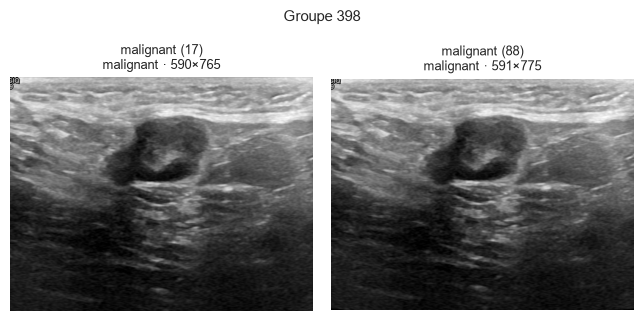

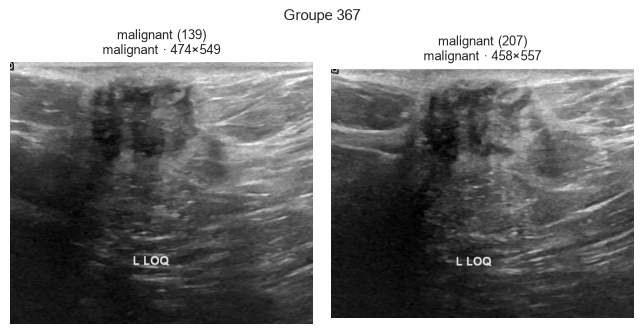

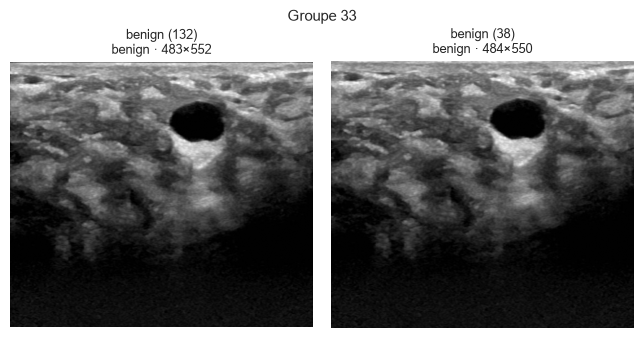

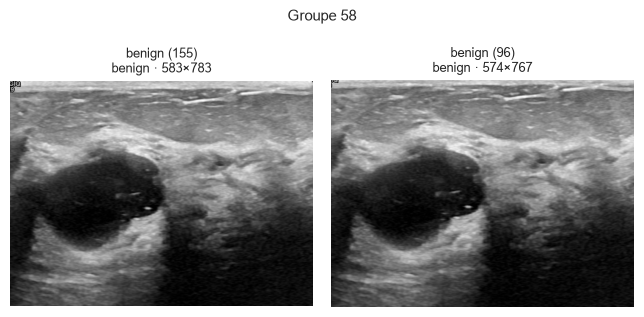

In [43]:
def afficher_groupe(groupe, titre=""):
    lignes = df_clean[df_clean["groupe"] == groupe].head(5)
    fig, axes = plt.subplots(1, len(lignes), figsize=(3.3 * len(lignes), 3.5))
    axes = np.atleast_1d(axes)
    for ax, (_, l) in zip(axes, lignes.iterrows()):
        ax.imshow(lire_image(l["image_path"]), cmap="gray")
        ax.set_title(f"{l['id']}\n{l['classe']} · {l['hauteur']}×{l['largeur']}", fontsize=9)
        ax.axis("off")
    fig.suptitle(titre, fontsize=11)
    plt.tight_layout()
    plt.show()

exemples = pd.Series(avec_copie["groupe"].unique()).sample(
    min(4, avec_copie["groupe"].nunique()), random_state=SEED)
for g in exemples:
    afficher_groupe(g, f"Groupe {g}")

#### Vérification des gros groupes

Avec l'union-find, si A ressemble à B et B ressemble à C, alors A, B et C sont réunis, **même si A et C ne se ressemblent pas directement**. Une chaîne de ressemblances pourrait donc réunir des échographies différentes. Les groupes de **4 images ou plus** sont les plus exposés à ce risque : on les affiche **en entier** pour les vérifier.

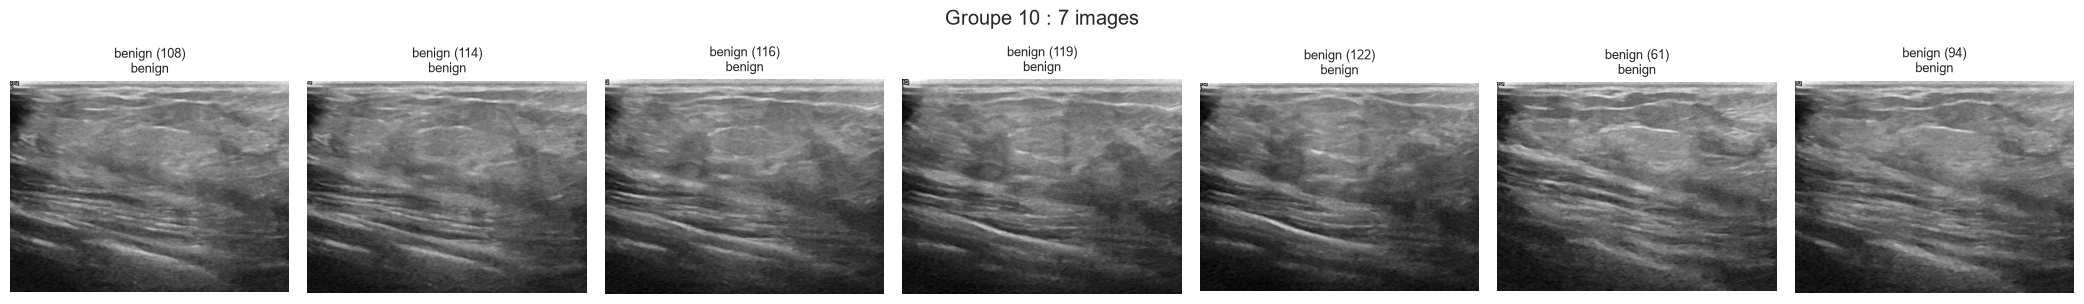

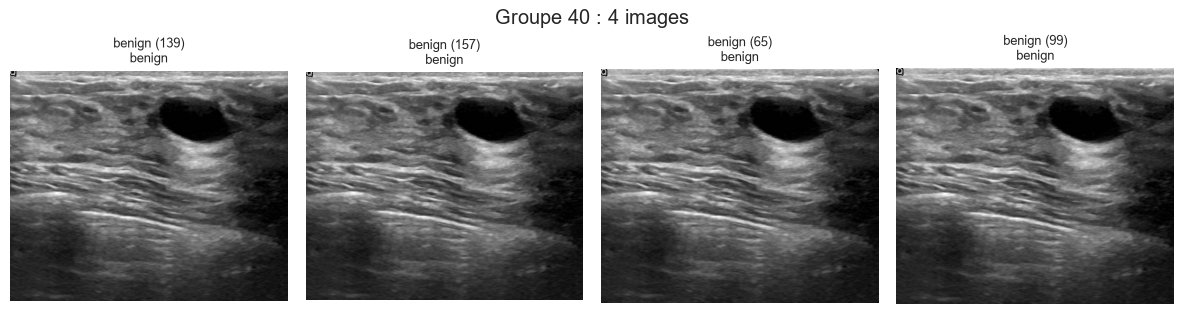

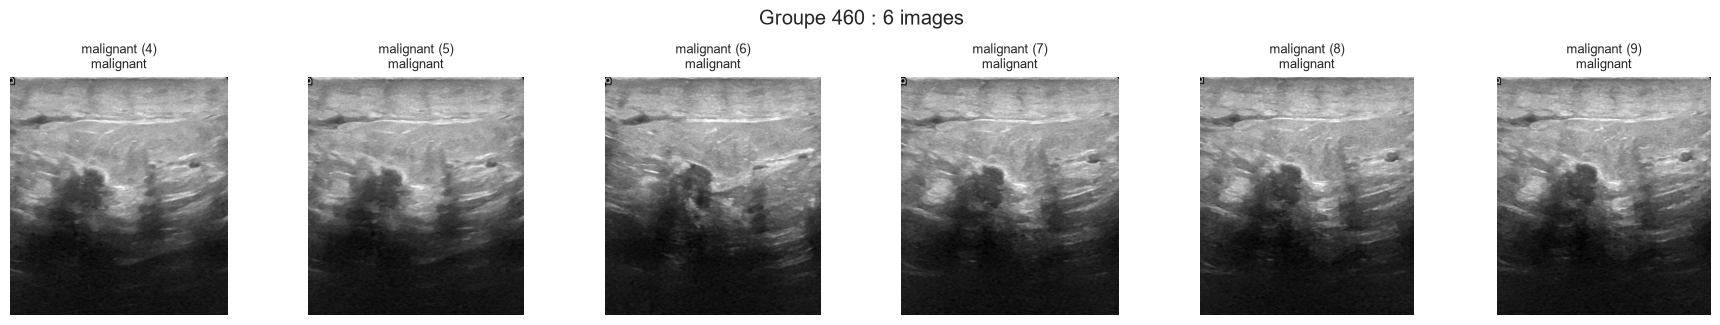

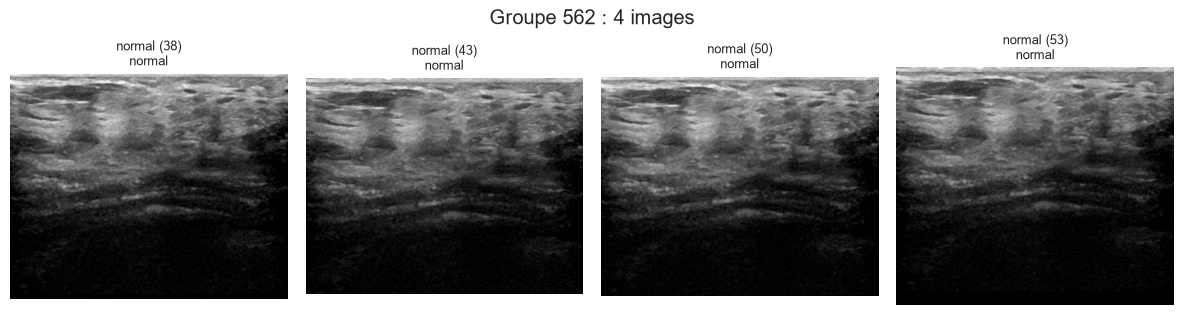

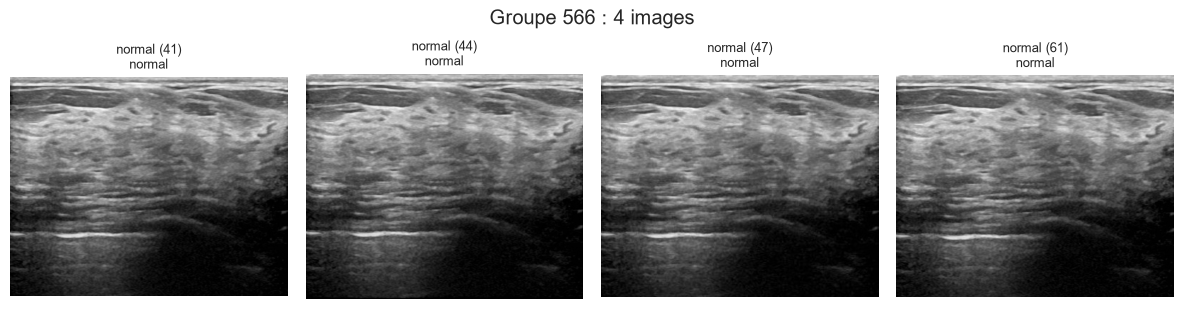

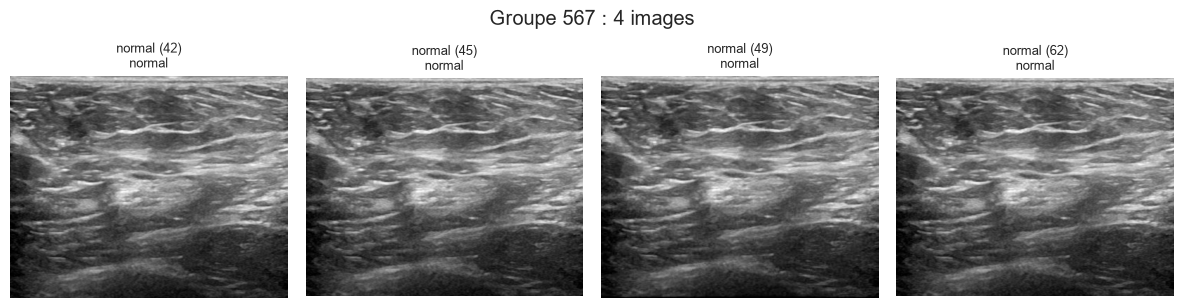

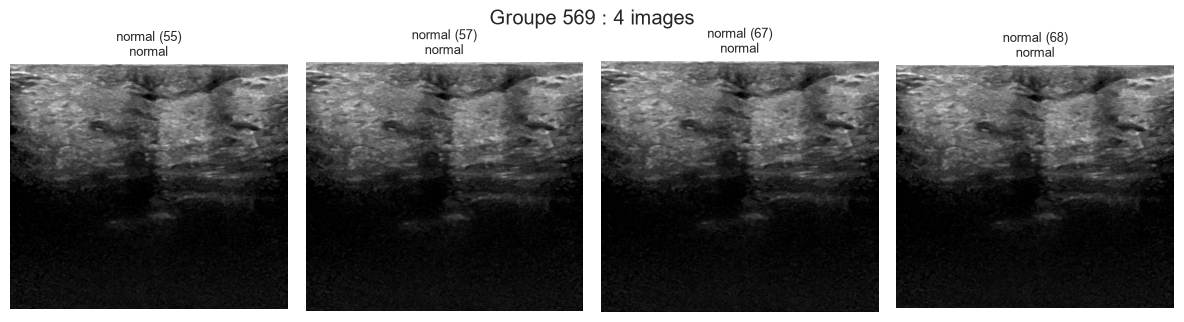

In [44]:
gros_groupes = avec_copie.groupby("groupe").size()
gros_groupes = gros_groupes[gros_groupes >= 4].index

for g in gros_groupes:
    lignes = df_clean[df_clean["groupe"] == g]
    fig, axes = plt.subplots(1, len(lignes), figsize=(3 * len(lignes), 3.3))
    for ax, (_, l) in zip(axes, lignes.iterrows()):
        ax.imshow(lire_image(l["image_path"]), cmap="gray")
        ax.set_title(f"{l['id']}\n{l['classe']}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Groupe {g} : {len(lignes)} images")
    plt.tight_layout()
    plt.show()

**Interprétation :** dans chaque gros groupe, les images montrent **la même zone du sein**, avec la même tumeur ou les mêmes structures, et seulement de légers décalages de cadrage ou de contraste. Leurs numéros sont souvent **consécutifs** (par exemple *malignant (4) à (9)*, *normal (41), (44), (47), (61)*).

Les groupes rassemblent donc non seulement des **copies retouchées** (redimensionnées, compressées), mais aussi des **captures successives d'un même examen** : le radiologue bouge légèrement la sonde et enregistre une nouvelle image. Il est indispensable de les garder dans la même partition. En l'absence d'identifiant patient dans BUSI, le découpage par groupe constitue ainsi **la meilleure approximation possible d'un découpage par patient**.

#### Groupes aux classes contradictoires

Certains groupes contiennent la même échographie étiquetée dans **deux classes différentes** (par exemple *benign* **et** *malignant*). On ne peut pas savoir quelle étiquette est la bonne : on les **affiche tous pour les vérifier à l'œil**, puis on les **retire**, comme on l'a fait pour le doublon exact en 2.4.

Groupes aux classes contradictoires : 7 (16 images)


,groupe,id,classe,hauteur,largeur
36,32,benign (131),benign,435,587
356,32,benign (42),benign,437,581
592,32,malignant (51),malignant,437,588
72,64,benign (164),benign,470,560
420,64,benign (85),benign,465,561
593,64,malignant (52),malignant,462,552
645,158,normal (1),normal,470,568
188,158,benign (269),benign,390,465
620,187,malignant (77),malignant,587,801
260,187,benign (333),benign,569,777


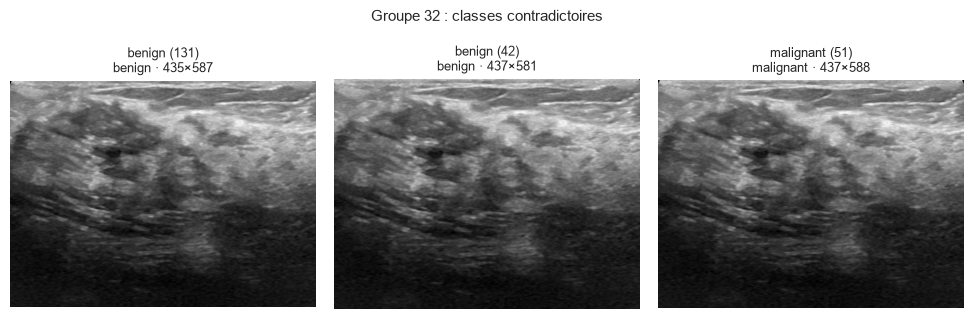

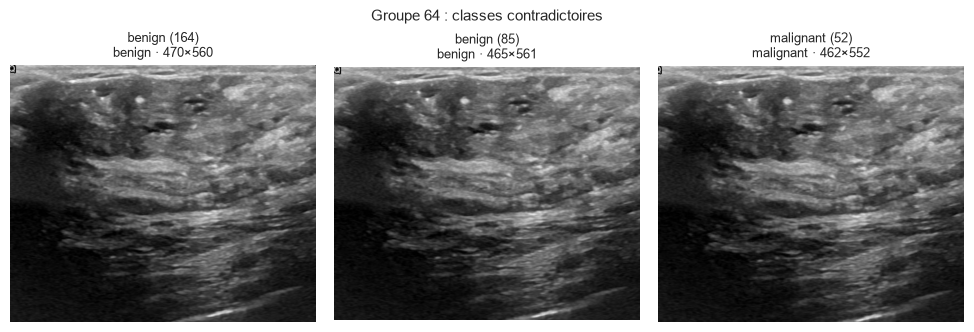

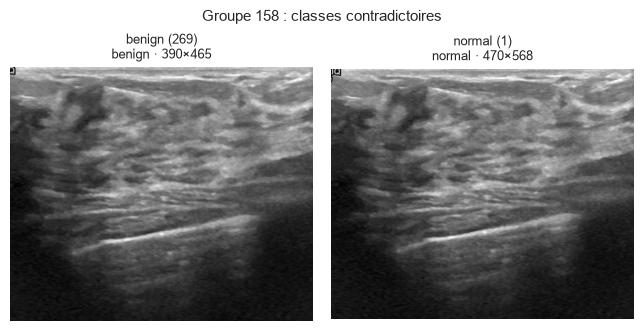

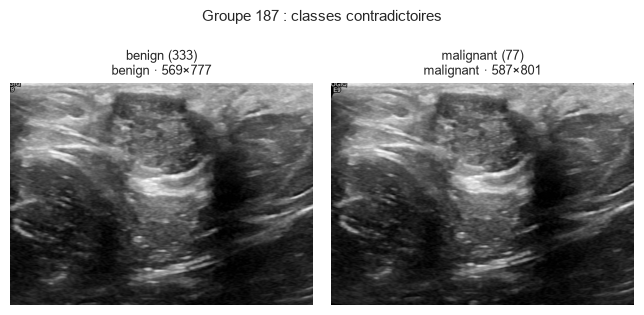

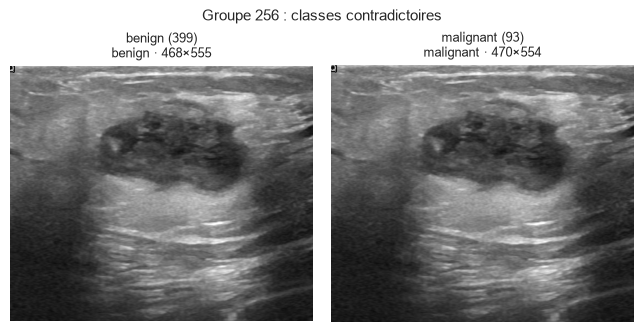

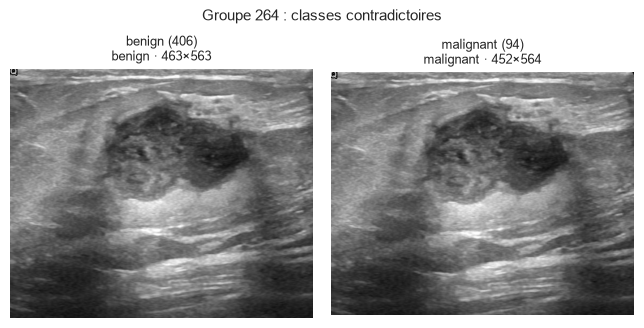

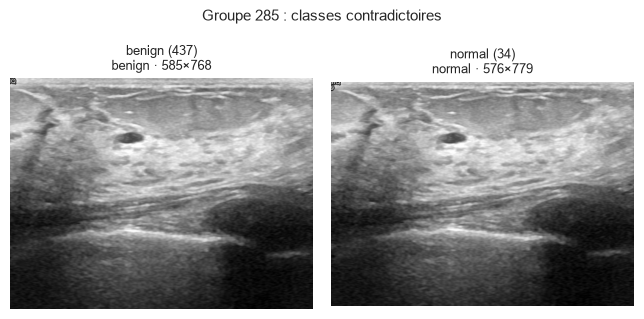

In [45]:
nb_classes = df_clean.groupby("groupe")["classe"].nunique()
groupes_conflit = nb_classes[nb_classes > 1].index

print(f"Groupes aux classes contradictoires : {len(groupes_conflit)} "
      f"({df_clean['groupe'].isin(groupes_conflit).sum()} images)")
display(df_clean[df_clean["groupe"].isin(groupes_conflit)]
        .sort_values("groupe")[["groupe", "id", "classe", "hauteur", "largeur"]])

for g in groupes_conflit:
    afficher_groupe(g, f"Groupe {g} : classes contradictoires")

**Résultat :** **7 groupes contradictoires** (16 images), le même nombre que dans la vérification de Hiba :

| Type de contradiction | Nombre de groupes |
|---|---|
| benign ↔ malignant | 5 |
| benign ↔ normal | 2 |

Les dimensions des images d'un même groupe ne diffèrent que de quelques pixels (par exemple 435×587, 437×581 et 437×588) : ce sont bien des versions retouchées d'une même échographie.

Le cas **benign ↔ normal** est le plus grave pour la segmentation : la même image aurait un masque **avec** tumeur dans un cas et un masque **vide** dans l'autre, donc deux réponses opposées pour le modèle. Faute de pouvoir déterminer l'étiquette correcte, **toutes les images de ces groupes sont retirées**.

#### Application

- les groupes **contradictoires** sont retirés ;
- **toutes les autres images sont gardées**, y compris les copies : elles ne posent pas de problème **tant que toutes les copies d'un groupe restent dans la même partition**. C'est ce que garantit le découpage **par groupe** de la partie 3.

In [46]:
avant = df_clean["classe"].value_counts().reindex(CLASSES)
df_clean = df_clean[~df_clean["groupe"].isin(groupes_conflit)].reset_index(drop=True)

bilan_qd = pd.DataFrame({"avant": avant,
                         "après": df_clean["classe"].value_counts().reindex(CLASSES)})
bilan_qd["retirées"] = bilan_qd["avant"] - bilan_qd["après"]
bilan_qd.loc["TOTAL"] = bilan_qd.sum()
display(bilan_qd)
print(f"Dataset final : {len(df_clean)} images, {df_clean['groupe'].nunique()} groupes")

,avant,après,retirées
classe,,,
benign,436,427,9
malignant,209,204,5
normal,133,131,2
TOTAL,778,762,16


Dataset final : 762 images, 598 groupes


**Bilan des quasi-doublons :**
- 216 paires détectées (pHash ≤ 12 et corrélation ≥ 0,85), regroupées en **137 groupes** totalisant 310 images.
- **7 groupes contradictoires** (16 images) retirés : 9 benign, 5 malignant, 2 normal.
- **Dataset final : 762 images** (427 benign, 204 malignant, 131 normal), soit **98 %** du dataset d'origine.
- Ces 762 images forment **598 groupes** : 130 groupes de copies (294 images) et 468 images sans copie.

C'est sur ces **598 groupes**, et non plus sur les images, que se fait le découpage.

---
## 3. Découpage train / validation / test

### Le rôle de chaque partition

| Partition | Part | Rôle |
|---|---|---|
| **Train** | 70 % | Le modèle **apprend** sur ces images |
| **Validation** | 15 % | On **choisit les hyperparamètres** (perte, learning rate, taille) en comparant les scores sur ces images |
| **Test** | 15 % | On mesure la **performance finale**, **une seule fois**, à la toute fin |

**Pourquoi trois partitions et pas deux ?** Si on choisissait les hyperparamètres en regardant le test, on « optimiserait » le modèle pour ces images précises : le score final serait trop optimiste. Le test doit rester **jamais vu** jusqu'à la fin.

### Comment on découpe : par groupe, pas par image

On ne découpe plus les **images** mais les **groupes** de la partie 2.5. Toutes les copies d'une même échographie partent ensemble dans **la même partition** : il devient impossible qu'une copie soit dans le train et une autre dans le test.

1. On construit un tableau avec **une ligne par groupe** et sa classe (unique, puisque les groupes contradictoires ont été retirés).
2. `train_test_split` est utilisé **deux fois** sur ce tableau : **70 %** des groupes pour le train, puis le reste coupé en deux, **15 %** validation et **15 %** test.
3. Chaque image reçoit la partition de son groupe.

`stratify=...["classe"]` garde **les mêmes proportions** de benign / malignant / normal dans chaque partition. `random_state=SEED` rend le découpage **reproductible**.

Comme les groupes n'ont pas tous la même taille, les parts en **nombre d'images** peuvent s'écarter un peu de 70 / 15 / 15 : on le vérifie juste après.

### Pourquoi « par groupe » et pas « par patient » ?

L'énoncé demande un split **par patient** quand c'est possible, pour qu'un même patient ne soit jamais à la fois dans le train et le test. Or **BUSI ne fournit pas d'identifiant patient**. Le découpage **par groupe de quasi-doublons** s'en approche le plus possible : il garantit qu'**une même échographie** n'est jamais dans deux partitions. Il reste possible que deux échographies *différentes* d'une même patiente soient séparées : c'est une **limite à mentionner dans le rapport**.

In [47]:
# Une ligne par groupe, avec sa classe et son nombre d'images
groupes_df = df_clean.groupby("groupe").agg(classe=("classe", "first"),
                                            nb_images=("id", "size")).reset_index()

g_train, g_reste = train_test_split(
    groupes_df, test_size=0.30, stratify=groupes_df["classe"], random_state=SEED)
g_val, g_test = train_test_split(
    g_reste, test_size=0.50, stratify=g_reste["classe"], random_state=SEED)

partition_du_groupe = {**dict.fromkeys(g_train["groupe"], "train"),
                       **dict.fromkeys(g_val["groupe"], "val"),
                       **dict.fromkeys(g_test["groupe"], "test")}
df_clean["split"] = df_clean["groupe"].map(partition_du_groupe)

ordre = ["train", "val", "test"]
parts = (df_clean["split"].value_counts(normalize=True).reindex(ordre) * 100).round(1)
print("Part des images dans chaque partition (%) :", dict(parts))
comptes = pd.crosstab(df_clean["classe"], df_clean["split"])[ordre]
comptes.loc["TOTAL"] = comptes.sum()
display(comptes)

proportions = (pd.crosstab(df_clean["classe"], df_clean["split"], normalize="columns")[ordre] * 100).round(1)
print("Proportion de chaque classe dans chaque partition (%) :")
display(proportions)

Part des images dans chaque partition (%) : {'train': np.float64(69.9), 'val': np.float64(15.5), 'test': np.float64(14.6)}


split,train,val,test
classe,,,
benign,303,62,62
malignant,140,33,31
normal,90,23,18
TOTAL,533,118,111


Proportion de chaque classe dans chaque partition (%) :


split,train,val,test
classe,,,
benign,56.8,52.5,55.9
malignant,26.3,28.0,27.9
normal,16.9,19.5,16.2


### Correction : 4 paires supplémentaires détectées par Hiba

En refaisant la détection sur ce nouveau découpage dans le notebook 02, avec ses propres réglages de corrélation, Hiba a trouvé **4 paires de quasi-doublons** que notre seuil n'avait pas regroupées. Dans chaque paire, une image est dans le **train** et l'autre dans la **validation** :

| Paire |
|---|
| benign (205) / benign (262) |
| benign (220) / benign (271) |
| benign (221) / benign (246) |
| normal (132) / normal (20) |

**Aucune ne touche le test**, donc l'évaluation finale n'était pas faussée. Mais ces paires gonflent un peu les scores de validation, qui servent à **choisir les hyperparamètres**.

**Correction :** pour chaque paire, l'image de la **validation** est **déplacée vers le train**, et les deux images sont réunies dans le même `groupe`. On ne touche pas au reste du découpage, pour que le test reste exactement le même.

In [48]:
PAIRES_HIBA = [("benign (205)", "benign (262)"),
               ("benign (220)", "benign (271)"),
               ("benign (221)", "benign (246)"),
               ("normal (132)", "normal (20)")]

for a, b in PAIRES_HIBA:
    lignes = df_clean[df_clean["id"].isin([a, b])]
    if len(lignes) != 2:
        print(f"⚠️ Paire {a} / {b} introuvable, ignorée")
        continue
    ref = lignes[lignes["split"] == "train"]
    a_deplacer = lignes[lignes["split"] == "val"]
    if len(ref) == 1 and len(a_deplacer) == 1:
        df_clean.loc[a_deplacer.index, "split"] = "train"
        df_clean.loc[lignes.index, "groupe"] = ref["groupe"].iloc[0]
        print(f"{a_deplacer['id'].iloc[0]} : val -> train (rejoint {ref['id'].iloc[0]})")
    else:
        print(f"Paire {a} / {b} : déjà dans la même partition ({', '.join(lignes['split'])})")

df_clean["taille_groupe"] = df_clean.groupby("groupe")["id"].transform("size")

# Nouveaux comptes (utilisés par le graphique et les contrôles qui suivent)
comptes = pd.crosstab(df_clean["classe"], df_clean["split"])[ordre]
comptes.loc["TOTAL"] = comptes.sum()
display(comptes)
proportions = (pd.crosstab(df_clean["classe"], df_clean["split"], normalize="columns")[ordre] * 100).round(1)
display(proportions)
parts = (df_clean["split"].value_counts(normalize=True).reindex(ordre) * 100).round(1)
print("Part des images dans chaque partition (%) :", dict(parts))

benign (205) : val -> train (rejoint benign (262))
benign (220) : val -> train (rejoint benign (271))
benign (246) : val -> train (rejoint benign (221))
normal (132) : val -> train (rejoint normal (20))


split,train,val,test
classe,,,
benign,306,59,62
malignant,140,33,31
normal,91,22,18
TOTAL,537,114,111


split,train,val,test
classe,,,
benign,57.0,51.8,55.9
malignant,26.1,28.9,27.9
normal,16.9,19.3,16.2


Part des images dans chaque partition (%) : {'train': np.float64(70.5), 'val': np.float64(15.0), 'test': np.float64(14.6)}


**Bilan du découpage par groupe (après correction) :**
- Train : **537** images (70,5 %) · Validation : **114** (15,0 %) · Test : **111** (14,6 %), inchangé.
- Les proportions de classes restent proches dans les trois partitions (écarts inférieurs à 4 points). Les petits écarts viennent du découpage **par blocs entiers** (dont un groupe de 7 images) : c'est le prix, faible, de la suppression de la fuite.
- Toutes les copies d'une même échographie sont dans la même partition.
- **Limite :** le test ne compte que **31 images malignes** et **18 normales** ; les résultats par classe sont à interpréter avec prudence.

### Vérification visuelle et contrôles anti-fuite

Le graphique doit montrer des barres de **même forme** dans les trois partitions : c'est la preuve que la stratification a fonctionné.

Les `assert` vérifient automatiquement deux règles. Si une règle n'est pas respectée, le notebook **s'arrête avec une erreur** :

1. aucune image n'apparaît dans deux partitions ;
2. aucune empreinte MD5 (`hash`) n'est partagée entre deux partitions : **aucun doublon exact** à cheval ;
3. aucun `groupe` n'est partagé entre deux partitions : **aucun quasi-doublon** à cheval.

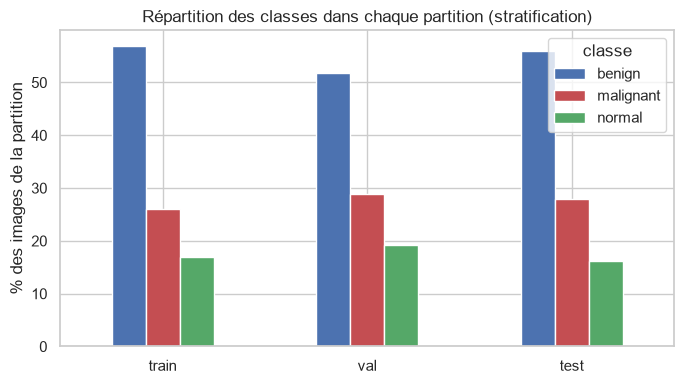

✅ Aucune fuite : aucune image, aucun doublon exact et aucun groupe de quasi-doublons partagé entre les partitions.


In [49]:
fig, ax = plt.subplots(figsize=(7, 4))
proportions.T.plot(kind="bar", ax=ax, color=[COULEURS[c] for c in proportions.index])
ax.set_ylabel("% des images de la partition")
ax.set_xlabel("")
ax.set_title("Répartition des classes dans chaque partition (stratification)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="classe")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/stratification_split.png", dpi=150)
plt.show()

# --- Contrôles anti-fuite ---
ids = {s: set(df_clean.loc[df_clean["split"] == s, "id"] + "|" + df_clean.loc[df_clean["split"] == s, "classe"]) for s in ordre}
hashes = {s: set(df_clean.loc[df_clean["split"] == s, "hash"]) for s in ordre}
grps = {s: set(df_clean.loc[df_clean["split"] == s, "groupe"]) for s in ordre}

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (ids[a] & ids[b]), f"Image commune entre {a} et {b} !"
    assert not (hashes[a] & hashes[b]), f"Doublon exact à cheval entre {a} et {b} !"
    assert not (grps[a] & grps[b]), f"Quasi-doublon à cheval entre {a} et {b} !"

print("✅ Aucune fuite : aucune image, aucun doublon exact et aucun groupe de quasi-doublons "
      "partagé entre les partitions.")

### Sauvegarde de `splits.csv`

C'est **le fichier le plus important de l'étape 1**. Il contient, pour chaque image, sa partition (`train`, `val` ou `test`). On le met sur GitHub, et **tous les autres notebooks le lisent** au lieu de refaire un découpage. C'est ce qui garantit que les **4 algorithmes sont comparés sur exactement les mêmes images**.

⚠️ **Règle du groupe : on ne relance jamais ce découpage** une fois `splits.csv` partagé.

On garde dans le fichier les colonnes utiles pour la suite (chemins, classe, taille de la tumeur pour l'analyse d'erreurs, numéro de `groupe`).

In [50]:
colonnes = ["id", "classe", "split", "image_path", "mask_paths",
            "nb_masques", "hauteur", "largeur", "ratio_tumeur", "hash", "groupe", "taille_groupe"]
df_clean[colonnes].to_csv("splits.csv", index=False)

print("splits.csv enregistré :", len(df_clean), "images")
display(df_clean["split"].value_counts().reindex(ordre).rename("nb_images").to_frame())

splits.csv enregistré : 762 images


,nb_images
split,
train,537
val,114
test,111


---
## 4. Fonctions partagées : `utils.py`

Pour que **tout le groupe** lise les images et les masques **exactement de la même façon**, on regroupe les fonctions communes dans un fichier `utils.py`. La commande magique `%%writefile` écrit le contenu de la cellule dans ce fichier au lieu de l'exécuter.

Dans les notebooks suivants, il suffira d'écrire :

```python
from utils import lire_image, lire_masque, charger_split
train = charger_split("train")
```

Les fonctions de **métriques** (Dice, IoU, mAP…) seront ajoutées à ce fichier dans le notebook 02.

In [51]:
%%writefile utils.py
# Fonctions partagées du projet MedVision Smart.
import cv2
import numpy as np
import pandas as pd

SEED = 42
SPLITS_CSV = "splits.csv"


def lire_image(chemin):
    # Lit une échographie en niveaux de gris (tableau 2D, valeurs 0-255).
    return cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)


def lire_masque(mask_paths):
    # Lit et fusionne (OU logique) tous les masques d'une image. Renvoie un tableau 0/1.
    masque = None
    for chemin in mask_paths.split(";"):
        m = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) > 0
        masque = m if masque is None else (masque | m)
    return masque.astype(np.uint8)


def charger_split(split=None, chemin=SPLITS_CSV):
    # Charge splits.csv ; si split = "train", "val" ou "test", ne garde que cette partition.
    df = pd.read_csv(chemin)
    if split is not None:
        df = df[df["split"] == split].reset_index(drop=True)
    return df

Overwriting utils.py


**Test rapide :** on importe `utils.py` comme le feront les autres notebooks, et on vérifie que le chargement de chaque partition fonctionne.

In [52]:
import importlib
import utils
importlib.reload(utils)

for s in ["train", "val", "test"]:
    part = utils.charger_split(s)
    print(f"{s:5s} : {len(part)} images")

exemple = utils.charger_split("train").iloc[0]
m = utils.lire_masque(exemple["mask_paths"])
print("Exemple :", exemple["id"], "| masque :", m.shape, "| valeurs :", np.unique(m))

train : 537 images
val   : 114 images
test  : 111 images
Exemple : benign (1) | masque : (471, 562) | valeurs : [0 1]


---
## 5. Synthèse

### Ce que l'exploration nous a appris

| Constat | Décision prise |
|---|---|
| 780 images, classes déséquilibrées (56 / 27 / 17 %) | Découpage **stratifié** par classe |
| 17 images ont plusieurs masques | Masques **fusionnés** par OU logique |
| 1 doublon exact (MD5) présent dans 2 classes | Les 2 copies **retirées** |
| **137 groupes de quasi-doublons** (310 images) : copies retouchées et captures d'un même examen | Détectés par **pHash + corrélation**, regroupés par union-find |
| **7 groupes contradictoires** (16 images) | Retirés : il reste **762 images** |
| L'ancien découpage par image laissait **68 groupes sur 137** à cheval | Découpage refait **par groupe** : 533 / 118 / 111 |
| 4 paires train/val supplémentaires trouvées par Hiba | Image de validation **déplacée vers le train** : **537 / 114 / 111**, aucune fuite |
| Tailles d'images variables | **Redimensionnement** à 128 ou 256 px (hyperparamètre) |
| Tailles de tumeurs très variables, petites tumeurs fréquentes | Analyse d'erreurs **par taille de tumeur** |
| Fond majoritaire dans chaque image | Comparaison des pertes **BCE+Dice** et **Dice** |
| Pas d'identifiant patient | Split **par groupe de quasi-doublons**, limite signalée dans le rapport |

### Fichiers produits

- **`splits.csv`** : le découpage officiel train / val / test (762 images, par groupe), à partager sur GitHub. **Ne jamais le refaire.**
- **`utils.py`** : les fonctions de lecture partagées.
- **`outputs/*.png`** : les figures pour le rapport.

### Suite

- **Notebook 02** : baseline d'Otsu + CNN encodeur-décodeur simple, fonctions de métriques.
- **Notebook 03** : U-Net et U-Net++ sur le GPU d'Anas, réglage des hyperparamètres sur la validation.
- **Notebook 04** : évaluation finale sur le test, tableau comparatif, analyse d'erreurs, choix du modèle.